# Note:
do dữ liệu đã kiểm tra ở bước 1 không bị thiếu nên việc xử lí và điện dữ liệu sẽ cancel và sẽ tiến thẳng tới bước kiểm tra Outlier

# Kiểm tra OUTLIER

In [66]:
import numpy as np
import pandas as pd

In [67]:

# 1. Hàm xử lý outlier bằng Z-score
def filter_outliers_z_score(df, col, threshold=3):
  """Lọc bỏ các giá trị ngoại lai (outlier) dựa trên Z-score.

  Thường dùng cho dữ liệu có độ lệch thấp (skewness nhỏ).
  """
  mean_val = df[col].mean()
  std_val = df[col].std()

  # Tính z-score cho từng giá trị
  z_scores = np.abs((df[col] - mean_val) / std_val)

  # Giữ lại các dòng có z-score nhỏ hơn ngưỡng (thường là 3)
  return df[z_scores <= threshold]


# 2. Hàm xử lý outlier bằng IQR (Interquartile Range)
def filter_outliers_iqr(df, col, multiplier=1.5):
  """Lọc bỏ các giá trị ngoại lai dựa trên khoảng tứ phân vị (IQR).

  Thường dùng cho dữ liệu có độ lệch trung bình.
  """
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - multiplier * IQR
  upper_bound = Q3 + multiplier * IQR

  # Giữ lại các dòng nằm trong khoảng cho phép
  return df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

## 1. Đọc dữ liệu

`TotalCharges` pandas đọc thành chữ (do có khoảng trắng) → phải chuyển sang số, không thì báo lỗi.

In [68]:
df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

import matplotlib.pyplot as plt

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
print('Số ô trống TotalCharges (sau khi chuyển số):', df['TotalCharges'].isna().sum())
df[num_cols].describe()

Số ô trống TotalCharges (sau khi chuyển số): 11


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


## 2. Xem outlier bằng mắt (boxplot)

Chấm đen ngoài khung là outlier.

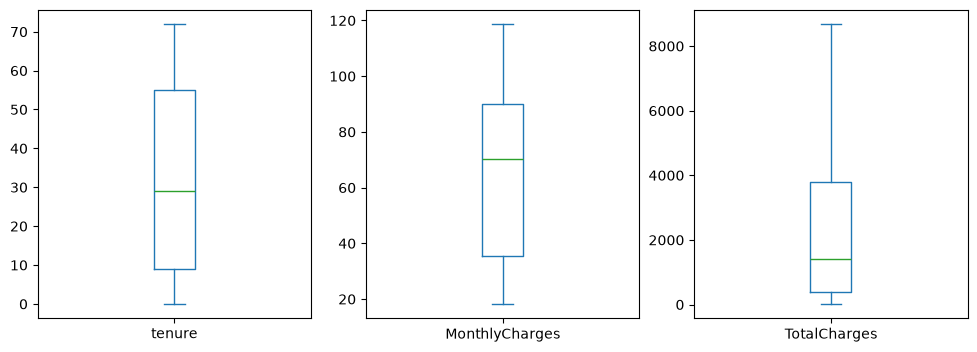

In [69]:
df[num_cols].plot(kind='box', subplots=True, layout=(1, 3), figsize=(12, 4))
plt.show()

## 3. Z-score

Giá trị cách trung bình quá xa (> 3 lần độ lệch chuẩn) là outlier.

In [70]:
print('Z-score - số outlier mỗi cột:')
for col in num_cols:
    n_out = len(df) - len(filter_outliers_z_score(df, col))
    print(f'  {col}: {n_out}')

Z-score - số outlier mỗi cột:
  tenure: 0
  MonthlyCharges: 0
  TotalCharges: 11


## 4. IQR

Nằm ngoài [Q1 - 1.5×IQR, Q3 + 1.5×IQR] là outlier.

In [71]:
print('IQR - số outlier mỗi cột:')
for col in num_cols:
    n_out = len(df) - len(filter_outliers_iqr(df, col))
    print(f'  {col}: {n_out}')

IQR - số outlier mỗi cột:
  tenure: 0
  MonthlyCharges: 0
  TotalCharges: 11


## 5. So sánh 2 phương pháp

In [72]:
rows = []
for col in num_cols:
    z = len(df) - len(filter_outliers_z_score(df, col))
    i = len(df) - len(filter_outliers_iqr(df, col))
    rows.append({'Cột': col, 'Z-score': z, 'IQR': i})

pd.DataFrame(rows)

,Cột,Z-score,IQR
0,tenure,0,0
1,MonthlyCharges,0,0
2,TotalCharges,11,11


### 1. Phương pháp kiểm tra Outlier

* **Z-score:** Những giá trị có $|Z| > 3$ (nằm cách giá trị trung bình hơn 3 lần độ lệch chuẩn) được coi là outlier.
* **IQR (Interquartile Range):** Những giá trị nằm ngoài khoảng $[Q_1 - 1.5 \times \text{IQR}, \, Q_3 + 1.5 \times \text{IQR}]$ được coi là outlier.
* **Kiểm tra trực quan:** Sử dụng biểu đồ `boxplot` để quan sát điểm dữ liệu nằm ngoài khung whiskers.

---

### 2. Kết quả đo được

| Cột | Số lượng Outlier (Z-score) | Số lượng Outlier (IQR) | Đánh giá |
| :--- | :---: | :---: | :--- |
| **tenure** | 0 | 0 | Không có outlier |
| **MonthlyCharges** | 0 | 0 | Không có outlier |
| **TotalCharges** | 11\* | 11\* | Thực tế không có outlier |




> **(\*) Ghi chú xử lý dữ liệu (`TotalCharges`):**
> Qua kiểm tra riêng xác nhận, 11 dòng dữ liệu bị ghi nhận ở trên thực chất là **các giá trị trống (`NaN`)** của cột `TotalCharges`. Do phép so sánh logic với `NaN` luôn trả về `False` trong Python nên bị các hàm lọc gắn nhầm nhãn. 
> 
> **Kết luận:** Số lượng outlier thực tế của cột `TotalCharges` bằng **0**. Biểu đồ Boxplot của cả 3 cột số đều không ghi nhận bất kỳ điểm dữ liệu nào nằm ngoài khoảng khung whiskers.

In [73]:
# Lọc bỏ các dòng có TotalCharges là khoảng trắng rỗng
empty_rows = df[df['TotalCharges'].astype(str).str.contains(r'^\s*$', na=True)]
print(f'Số lượng dòng rỗng tìm thấy: {len(empty_rows)}')
display(empty_rows)

Số lượng dòng rỗng tìm thấy: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [74]:
df.shape

(7043, 21)

In [75]:
# Lọc giữ lại các dòng không chứa khoảng trắng rỗng
df = df[~df['TotalCharges'].astype(str).str.contains(r'^\s*$', na=True)]

# Reset lại index sau khi xóa dòng (tùy chọn)
df = df.reset_index(drop=True)

print(f'Số dòng sau khi đã loại bỏ: {len(df)}')

Số dòng sau khi đã loại bỏ: 7032


Xóa dữ liệu bị null 
- Dữ liệu thiếu chiểm tỉ lệ ít  
- Dữ liệu có taget là NO (gía trị lớn nhất trong taget)

In [77]:
# Lưu ra file CSV, index=False để không ghi thêm cột chỉ số mặc định
df.to_csv('../data/cleaned/cleaned_telco_churn.csv', index=False, encoding='utf-8')
print("Đã lưu thành công file cleaned_telco_churn.csv!")

Đã lưu thành công file cleaned_telco_churn.csv!
